In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [6]:

model_repo = "Jayyydyyy/m2m100_418m_tokipona"
tokenizer_repo = "facebook/m2m100_418M"

print("Loading tokenizer and model...")
tokenizer = AutoTokenizer.from_pretrained(tokenizer_repo)
model = AutoModelForSeq2SeqLM.from_pretrained(model_repo, output_attentions=True)

Loading tokenizer and model...


The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Loading weights: 100%|██████████| 512/512 [00:00<00:00, 48498.92it/s]
M2M100ForConditionalGeneration LOAD REPORT from: Jayyydyyy/m2m100_418m_tokipona
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
model.encoder.embed_positions.weights | UNEXPECTED |  | 
model.decoder.embed_positions.weights | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [13]:

# 2. Configure Languages (The fine-tuner repurposed Tagalog 'tl' for Toki Pona)
src_lang = "en"
tgt_lang = "tl"

tokenizer.src_lang = src_lang
tokenizer.tgt_lang = tgt_lang

def get_translation_with_attention(text):
    # Prepare input
    inputs = tokenizer(text, return_tensors="pt")
    
    # Generate translation 
    outputs = model.generate(
        **inputs, 
        output_attentions=True, 
        return_dict_in_generate=True,
        forced_bos_token_id=tokenizer.lang_code_to_id[tgt_lang]
    )
    
    # Decode the output
    decoded_output = tokenizer.batch_decode(outputs.sequences, skip_special_tokens=True)[0]
    
    # Extract Cross-Attention (Encoder-Decoder Attention)
    cross_attentions = outputs.cross_attentions 
    
    return {
        "english": text,
        "toki_pona": decoded_output,
        "input_tokens": tokenizer.convert_ids_to_tokens(inputs['input_ids'][0]),
        "output_tokens": tokenizer.convert_ids_to_tokens(outputs.sequences[0]),
        "attentions": cross_attentions
    }

def extract_attention_vectors(data, layer=-1):
    """
    Collapses multi-head attention into a single 2D semantic map.
    """
    all_layers = data["attentions"]
    
    combined_map = []
    # Cross-attention is generated token-by-token
    for token_step in all_layers:
        # token_step[layer] shape: (num_beams, num_heads, 1, src_len)
        # 1. Slice [0] to get the top beam only -> (num_heads, 1, src_len)
        # 2. .mean(dim=0) to average across all attention heads -> (1, src_len)
        # 3. .squeeze() to drop the 1 -> (src_len,)
        avg_head_attn = token_step[layer][0].mean(dim=0).squeeze().detach().cpu().numpy()
        combined_map.append(avg_head_attn)
        
    return np.array(combined_map)

Translating: 'Workers of the world, unite!'...
Toki Pona: jan pali pi ma ale o wan!


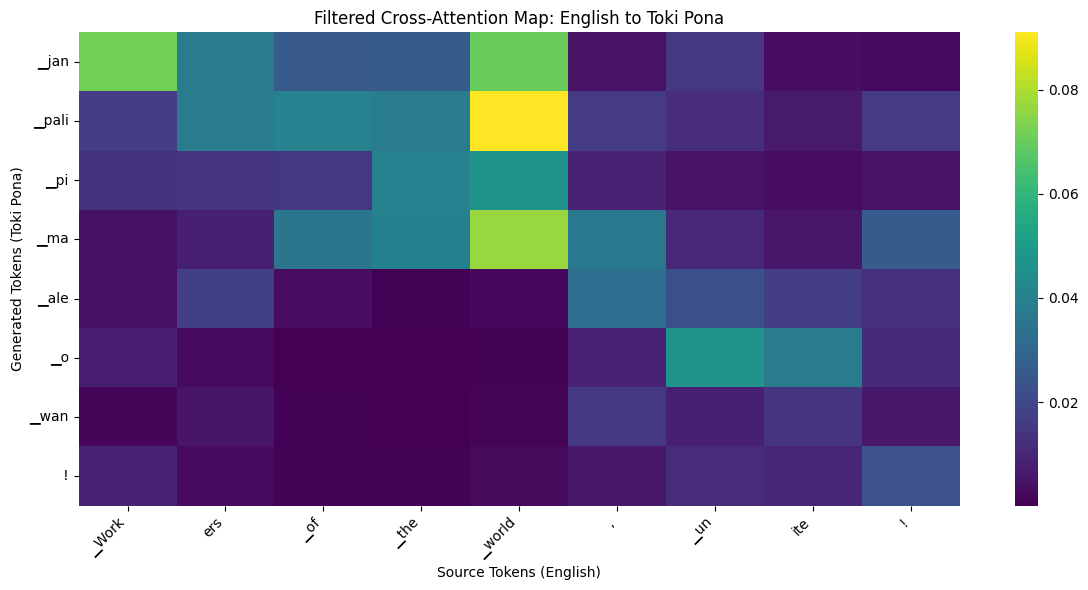

In [16]:
text_to_translate = "Workers of the world, unite!"
print(f"Translating: '{text_to_translate}'...")
result = get_translation_with_attention(text_to_translate)
attn_matrix = extract_attention_vectors(result)

print(f"Toki Pona: {result['toki_pona']}")


attn_matrix = extract_attention_vectors(result)

# Clean up tokens for the graph
clean_in_tokens = [t.replace(' ', '') for t in result["input_tokens"]]
clean_out_tokens = [t.replace(' ', '') for t in result["output_tokens"]]

# Align target tokens with matrix rows
clean_out_tokens = clean_out_tokens[-attn_matrix.shape[0]:]

# --- NEW: FILTER OUT SPECIAL TOKENS ---
# Define the exact special tokens you want to hide
ignore_tokens = {"</s>", "__tl__", "__en__"}

# Find the indices of the real words we ACTUALLY want to keep
keep_src_indices = [i for i, t in enumerate(clean_in_tokens) if t not in ignore_tokens]
keep_tgt_indices = [i for i, t in enumerate(clean_out_tokens) if t not in ignore_tokens]

# Filter the token lists for the axis labels
filtered_in_tokens = [clean_in_tokens[i] for i in keep_src_indices]
filtered_out_tokens = [clean_out_tokens[i] for i in keep_tgt_indices]

# Filter the matrix using numpy indexing to slice out the ignored rows and columns
filtered_matrix = attn_matrix[keep_tgt_indices, :][:, keep_src_indices]

# --- GRAPHING ---
plt.figure(figsize=(12, 6))

# Notice we are using filtered_matrix, filtered_in_tokens, and filtered_out_tokens now
sns.heatmap(filtered_matrix, 
            xticklabels=filtered_in_tokens, 
            yticklabels=filtered_out_tokens, 
            annot=False, cmap="viridis", cbar=True)

plt.title("Filtered Cross-Attention Map: English to Toki Pona")
plt.xlabel("Source Tokens (English)")
plt.ylabel("Generated Tokens (Toki Pona)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# If you are saving vectors to a database later, you should probably save 
# the 'filtered_matrix' so your stored vectors only contain the real words!